# 64 Squares — Exploration des données (EDA)

Exploration de l'échantillon de parties Lichess (parties classées standard, septembre 2026) **après nettoyage**.
Objectif : comprendre la forme des données avant l'analyse (`src/eloscope/analyze.py`) et vérifier la qualité.

Prérequis : `python run.py ingest clean model` (ce notebook lit `data/processed/` et `data/eloscope.duckdb`).

In [1]:
import json
import sys
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
from eloscope import charts  # noqa: E402  (registers the project plotly template)
from eloscope.analyze import _configure_browser, wilson_interval  # noqa: E402

_configure_browser()
pio.renderers.default = "png"  # static images: the notebook renders on GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 1000, 480
pd.set_option("display.max_columns", 30, "display.width", 160)

con = duckdb.connect(str(ROOT / "data" / "eloscope.duckdb"), read_only=True)
games = pd.read_parquet(ROOT / "data" / "processed" / "games_clean.parquet")
report = json.loads((ROOT / "data" / "processed" / "cleaning_report.json").read_text(encoding="utf-8"))
print(f"{len(games):,} parties nettoyées, {games.shape[1]} colonnes")

1,958,145 parties nettoyées, 47 colonnes


## 1. Du fichier brut à la table propre
Nombre de lignes avant / après chaque règle de nettoyage (détail dans `docs/methodology.md`).

In [2]:
rules = pd.DataFrame(report["rules"])[["rule", "description", "rows_before", "rows_after", "removed"]]
rules["removed_pct"] = (rules["removed"] / rules["rows_before"] * 100).round(3)
print(f"Échantillon brut : {report['rows_in']:,} parties -> table propre : {report['rows_out']:,} ({report['rows_out'] / report['rows_in']:.1%})")
rules

Échantillon brut : 2,000,201 parties -> table propre : 1,958,145 (97.9%)


,rule,description,rows_before,rows_after,removed,removed_pct
0,R0,Duplicate game ids removed,2000201,2000201,0,0.000
1,R1,"Rated standard games only (no variant, no casual)",2000201,2000201,0,0.000
2,R2,"Termination in ['Normal', 'Time forfeit'] and ...",2000201,1989868,10333,0.517
3,R3,At least 10 plies,1989868,1968850,21018,1.056
4,R4,No BOT account on either side,1968850,1959293,9557,0.485
5,R5,"Both ratings present, numeric and within 400-3200",1959293,1959167,126,0.006
6,R6,Valid base+increment time control (corresponde...,1959167,1958145,1022,0.052


In [3]:
pd.Series({k: v for k, v in report["checks"].items() if not isinstance(v, dict)}, name="valeur").to_frame()

,valeur
event_speed_matches_tc_category,1.000000
opening_name_in_reference,0.998690
has_clock,1.000000
has_time_used_10,0.968266
has_eval,0.101009
berserk_any,0.016228


## 2. Qualité des colonnes
Valeurs manquantes : seules les colonnes d'horloge (parties trop courtes pour 10 coups) et les variations d'ouverture (nom sans « : ») en ont.

In [4]:
missing = games.isna().mean().sort_values(ascending=False)
missing[missing > 0].rename("part manquante").to_frame().style.format("{:.2%}")

,part manquante
black_title,99.54%
white_title,99.53%
time_loser,68.51%
opening_variation,32.34%
black_time_used_10,3.59%
white_time_used_10,3.17%
black_clk_10,2.86%
black_time_used_10_s,2.86%
white_time_used_10_s,2.44%
white_clk_10,2.44%


## 3. Qui joue ? Niveaux et cadences

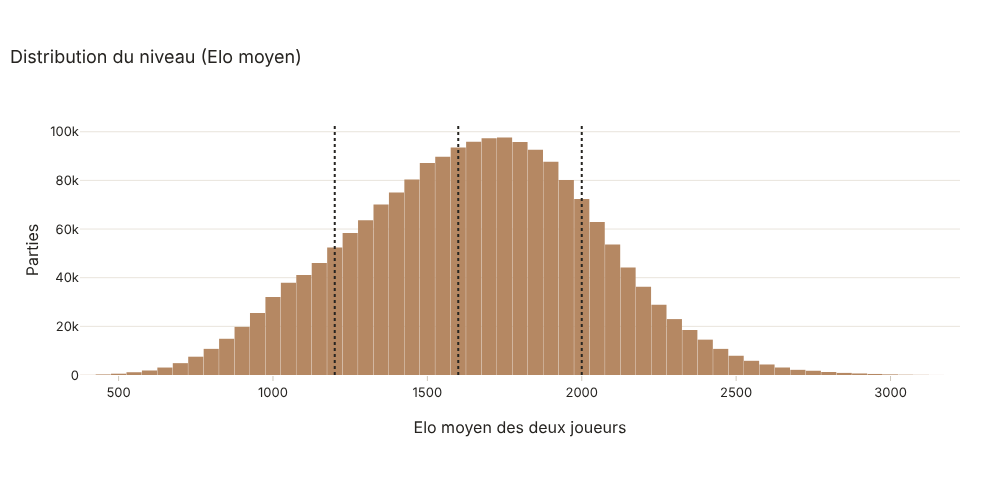

,count,mean,std,min,25%,50%,75%,max
avg_elo,1958145.0,1644.3,390.1,400.0,1373.0,1657.0,1915.5,3184.5


In [5]:
fig = px.histogram(games, x="avg_elo", nbins=70, color_discrete_sequence=[charts.DARK_SQUARE],
                   labels={"avg_elo": "Elo moyen des deux joueurs"}, title="Distribution du niveau (Elo moyen)")
for edge in (1200, 1600, 2000):
    fig.add_vline(x=edge, line=dict(color=charts.INK, dash="dot"))
fig.update_layout(yaxis_title="Parties", bargap=0.02)
fig.show()
games["avg_elo"].describe().round(1).to_frame().T

In [6]:
mix = pd.crosstab(games["tc_category"], games["elo_band"], normalize="all").reindex(
    ["ultrabullet", "bullet", "blitz", "rapid", "classical"]).fillna(0)
(mix * 100).round(2).style.format("{:.2f} %").set_caption("Part des parties par cadence × tranche Elo")

elo_band,1200-1599,1600-1999,2000+,< 1200
tc_category,,,,
ultrabullet,0.27 %,0.47 %,0.17 %,0.04 %
bullet,8.57 %,13.05 %,10.67 %,3.22 %
blitz,15.07 %,18.09 %,6.35 %,6.57 %
rapid,6.36 %,5.49 %,1.00 %,4.02 %
classical,0.27 %,0.23 %,0.03 %,0.06 %


## 4. Les parties : longueur, fins de partie, écarts de classement

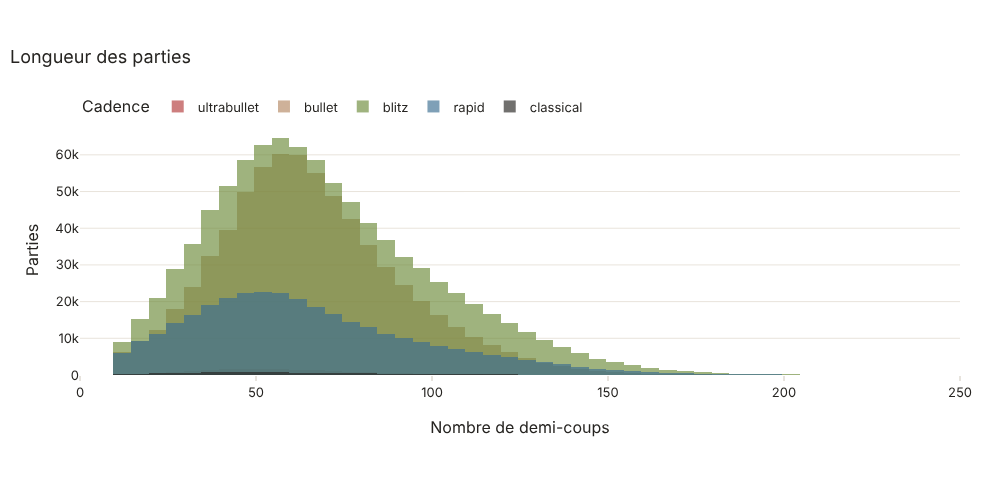

tc_category,blitz,bullet,classical,rapid,ultrabullet
médiane des demi-coups,64.0,63.0,59.0,60.0,55.0


In [7]:
fig = px.histogram(games, x="plies", nbins=120, range_x=[0, 250], color="tc_category",
                   category_orders={"tc_category": ["ultrabullet", "bullet", "blitz", "rapid", "classical"]},
                   color_discrete_sequence=[charts.RED, charts.DARK_SQUARE, charts.GREEN, charts.BLUE, charts.INK],
                   labels={"plies": "Nombre de demi-coups", "tc_category": "Cadence"}, title="Longueur des parties")
fig.update_layout(yaxis_title="Parties", barmode="overlay")
fig.update_traces(opacity=0.65)
fig.show()
games.groupby("tc_category")["plies"].median().rename("médiane des demi-coups").to_frame().T

In [8]:
pd.crosstab(games["tc_category"], games["termination"], normalize="index").round(4)

termination,Normal,Time forfeit
tc_category,,
blitz,0.7656,0.2344
bullet,0.4712,0.5288
classical,0.9255,0.0745
rapid,0.8935,0.1065
ultrabullet,0.2124,0.7876


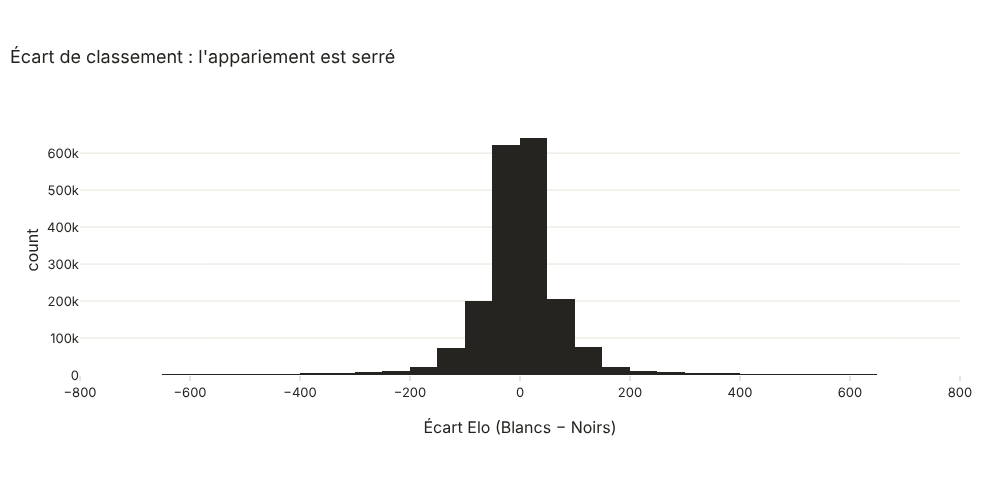

Écart absolu médian : 32 points ; 85.5% des parties à moins de 100 points ; 0.68% au-delà de 600 (tranche plafonnée)


In [9]:
fig = px.histogram(games, x="rating_gap", nbins=160, range_x=[-800, 800], color_discrete_sequence=[charts.INK],
                   labels={"rating_gap": "Écart Elo (Blancs − Noirs)"}, title="Écart de classement : l'appariement est serré")
fig.show()
print(f"Écart absolu médian : {games['rating_gap'].abs().median():.0f} points ; "
      f"{(games['rating_gap'].abs() <= 100).mean():.1%} des parties à moins de 100 points ; "
      f"{(games['rating_gap'].abs() > 600).mean():.2%} au-delà de 600 (tranche plafonnée)")

## 5. L'horloge : temps consommé sur les 10 premiers coups

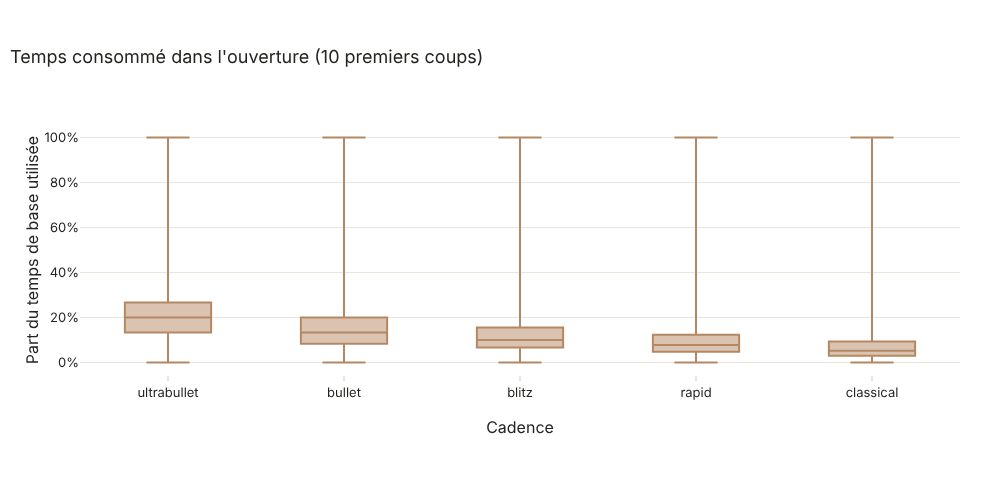

,count,mean,std,min,10%,50%,90%,max
tc_category,,,,,,,,
blitz,1759841.0,0.124,0.090,0.0,0.044,0.100,0.233,1.0
bullet,1333182.0,0.154,0.101,0.0,0.058,0.133,0.267,1.0
classical,22165.0,0.077,0.089,0.0,0.017,0.052,0.155,1.0
rapid,632396.0,0.098,0.076,0.0,0.033,0.078,0.185,1.0
ultrabullet,36242.0,0.233,0.158,0.0,0.067,0.200,0.400,1.0


In [10]:
clock = games.melt(id_vars=["tc_category"], value_vars=["white_time_used_10", "black_time_used_10"],
                   var_name="camp", value_name="part").dropna()
fig = px.box(clock, x="tc_category", y="part", points=False,
             category_orders={"tc_category": ["ultrabullet", "bullet", "blitz", "rapid", "classical"]},
             color_discrete_sequence=[charts.DARK_SQUARE],
             labels={"tc_category": "Cadence", "part": "Part du temps de base utilisée"},
             title="Temps consommé dans l'ouverture (10 premiers coups)")
fig.update_yaxes(tickformat=".0%")
fig.show()
clock.groupby("tc_category")["part"].describe(percentiles=[0.1, 0.5, 0.9]).round(3)

## 6. Les ouvertures : une longue traîne

In [11]:
fam = games["opening_family"].value_counts()
share = fam.cumsum() / fam.sum()
print(f"{fam.size} familles d'ouverture, {games['opening'].nunique()} noms complets ; "
      f"les 10 premières familles couvrent {share.iloc[9]:.1%} des parties, les 30 premières {share.iloc[29]:.1%}")
print(f"Noms absents du référentiel lichess-org/chess-openings : {1 - games['opening_in_reference'].mean():.2%}")
fam.head(15).rename("parties").to_frame()

146 familles d'ouverture, 2756 noms complets ; les 10 premières familles couvrent 51.9% des parties, les 30 premières 83.1%
Noms absents du référentiel lichess-org/chess-openings : 0.13%


,parties
opening_family,
Sicilian Defense,188222
Queen's Pawn Game,182486
French Defense,125888
Caro-Kann Defense,111920
Scandinavian Defense,108287
Italian Game,80937
English Opening,58872
King's Pawn Game,58566
Queen's Gambit Declined,52350


## 7. Premier regard sur les questions métier
Score des Blancs par tranche Elo avec intervalle de confiance de Wilson à 95 % sur le taux de victoire.

In [12]:
by_band = games.groupby("elo_band", observed=True).agg(
    parties=("white_score", "size"), score_blancs=("white_score", "mean"),
    victoires_blancs=("winner", lambda s: (s == "white").sum()), nulles=("winner", lambda s: (s == "draw").sum()))
by_band["taux_victoire_blancs"] = by_band["victoires_blancs"] / by_band["parties"]
low, high = wilson_interval(by_band["victoires_blancs"], by_band["parties"])
by_band["ic95_bas"], by_band["ic95_haut"] = low, high
by_band["taux_nulles"] = by_band["nulles"] / by_band["parties"]
by_band.loc[["< 1200", "1200-1599", "1600-1999", "2000+"]].round(4)

,parties,score_blancs,victoires_blancs,nulles,taux_victoire_blancs,ic95_bas,ic95_haut,taux_nulles
elo_band,,,,,,,,
< 1200,272553,0.5155,135836,9320,0.4984,0.4965,0.5003,0.0342
1200-1599,597855,0.5148,298237,19029,0.4988,0.4976,0.5001,0.0318
1600-1999,731067,0.5154,362955,27664,0.4965,0.4953,0.4976,0.0378
2000+,356670,0.5191,176487,17319,0.4948,0.4932,0.4965,0.0486


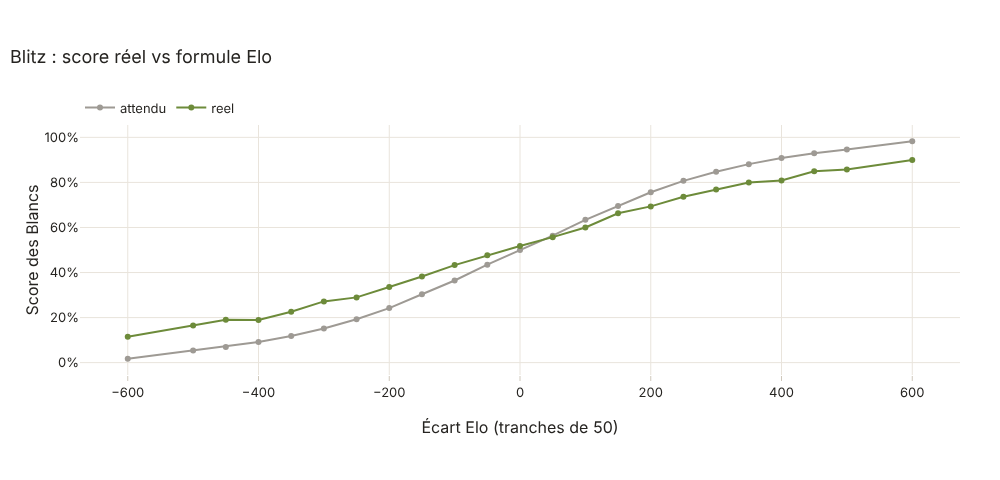

In [13]:
calib = con.sql("""
    SELECT tc_label, rating_gap_bucket, COUNT(*) AS n, AVG(expected_score) AS attendu, AVG(white_score) AS reel
    FROM v_games WHERE tc_label = 'Blitz' GROUP BY ALL HAVING COUNT(*) >= 1000 ORDER BY rating_gap_bucket""").df()
fig = px.line(calib, x="rating_gap_bucket", y=["attendu", "reel"], markers=True,
              color_discrete_sequence=[charts.GREY, charts.GREEN],
              labels={"rating_gap_bucket": "Écart Elo (tranches de 50)", "value": "Score des Blancs", "variable": ""},
              title="Blitz : score réel vs formule Elo")
fig.update_yaxes(tickformat=".0%")
fig.show()

## 8. Ce que l'exploration nous apprend

* Les données sont propres après nettoyage : aucune valeur manquante hors horloge / variations, cadence déduite du `TimeControl` cohérente à 100 % avec l'en-tête `Event`.
* L'appariement Lichess est serré (écart médian faible) : les tranches d'écart extrêmes ont peu de parties, d'où la règle du minimum de 1 000 parties par groupe.
* Le bullet et le blitz dominent l'échantillon ; les comparaisons entre niveaux doivent donc se faire **à cadence égale**.
* Les familles d'ouverture forment une longue traîne : on se concentre sur les plus jouées par tranche.

La suite (tests statistiques, calibration Elo, régression logistique) est dans `src/eloscope/analyze.py` et `reports/findings.md`.

In [14]:
con.close()